# **Projeto de Parceria — Previsão de Churn de Clientes (Telecom/ISP)**
### Escola Britânica de Artes Criativas & Tecnologia (EBAC) × Semantix — "Profissão: Cientista de Dados"

**Autora:** Marina Gomes


## 1. Problema de negócio

**Contexto:** uma empresa de telecomunicações (provedora de internet, telefonia fixa/móvel e TV por assinatura/streaming) perde uma parcela relevante da sua base de clientes todos os meses — o fenômeno conhecido como **churn**. Para um time de Customer Success/Retenção, cada cliente que cancela representa não só a perda da receita recorrente (assinatura mensal), mas também o custo de aquisição que já foi investido para conquistá-lo, que não será mais recuperado.

**Por que dados e Machine Learning ajudam a resolver esse problema:** se a empresa só descobre que um cliente vai cancelar no momento em que ele liga pedindo o cancelamento, a oportunidade de retê-lo já passou. Um modelo preditivo permite **identificar, com antecedência, quais clientes têm maior probabilidade de cancelar**, a partir de características do seu contrato, forma de pagamento e serviços contratados — permitindo que o time de retenção atue de forma **proativa** (oferta de desconto, migração de plano, contato consultivo) em vez de reativa, focando o esforço (e o orçamento de retenção) nos clientes de maior risco.

**Tarefa de Machine Learning:** classificação binária.

**Variável-alvo:** `Churn` — `Yes` (cliente cancelou) / `No` (cliente permanece ativo).

**Conexão com minha experiência:** atuo como Customer Success Manager em publicidade digital (CTV), lidando diariamente com relacionamento e retenção de contas — a lógica de negócio deste projeto (identificar sinais de risco antes da perda do cliente) é a mesma lógica que aplico no meu trabalho, só que aqui resolvida com um modelo estatístico em vez de acompanhamento manual.

## 2. Coleta de dados — fonte

**Fonte:** [Telco Customer Churn Dataset](https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv) — base pública disponibilizada pela IBM (também amplamente distribuída na comunidade de ciência de dados, incluindo o Kaggle, como *"Telco Customer Churn"*), usada para fins educacionais e de benchmarking de modelos de churn.

**Natureza dos dados:** a base é **sintética/anonimizada para fins didáticos** — não contém dados reais de clientes de nenhuma operadora, não há nomes, documentos ou qualquer dado pessoal identificável além de um `customerID` artificial. É uma fonte **pública e não confidencial**, adequada para um projeto de portfólio.

**Volume:** 7.043 clientes, 21 colunas — dados demográficos (gênero, idade sênior, dependentes), de contrato (tipo de contrato, forma de pagamento, cobrança sem papel), de serviços contratados (internet, telefone, segurança online, suporte técnico, **streaming de TV e filmes**) e financeiros (cobrança mensal, cobrança total, tempo de permanência/`tenure`).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_auc_score, roc_curve,
    f1_score, accuracy_score
)

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100
RANDOM_STATE = 42

In [2]:
df = pd.read_csv("data/Telco-Customer-Churn.csv")
print("Formato da base:", df.shape)
df.head()

Formato da base: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 3. Análise Exploratória de Dados (EDA)

### Técnica 1 — Estrutura geral: tipos, nulos e uma armadilha escondida em `TotalCharges`

In [3]:
print(df.dtypes.value_counts())
print()
print("Valores nulos por coluna (total):", df.isnull().sum().sum())
print("Linhas duplicadas:", df.duplicated().sum())
print()
# TotalCharges veio como texto (object) — isso é suspeito para uma coluna financeira
print("Valores não numéricos em TotalCharges:")
nao_numerico = df[pd.to_numeric(df["TotalCharges"], errors="coerce").isna()]
print(nao_numerico[["customerID", "tenure", "MonthlyCharges", "TotalCharges"]])

str        18
int64       2
float64     1
Name: count, dtype: int64

Valores nulos por coluna (total): 0
Linhas duplicadas: 0

Valores não numéricos em TotalCharges:
      customerID  tenure  MonthlyCharges TotalCharges
488   4472-LVYGI       0           52.55             
753   3115-CZMZD       0           20.25             
936   5709-LVOEQ       0           80.85             
1082  4367-NUYAO       0           25.75             
1340  1371-DWPAZ       0           56.05             
3331  7644-OMVMY       0           19.85             
3826  3213-VVOLG       0           25.35             
4380  2520-SGTTA       0           20.00             
5218  2923-ARZLG       0           19.70             
6670  4075-WKNIU       0           73.35             
6754  2775-SEFEE       0           61.90             


**Armadilha estrutural identificada:** `TotalCharges` está tipada como texto (`object`), não como número — e ao investigar o motivo, encontramos **11 linhas com string vazia** (`" "`) em vez de um valor numérico. Todas essas 11 linhas têm `tenure = 0`, ou seja, são **clientes recém-cadastrados que ainda não completaram um ciclo de cobrança** — por isso não têm "cobrança total" ainda. Não é um erro aleatório de digitação; é uma consequência lógica do negócio (cliente novo, sem fatura fechada), e precisa ser tratada dessa forma na preparação dos dados, não descartada ou imputada com a mediana sem critério.

### Técnica 2 — Distribuição da variável-alvo (desbalanceamento de classes)

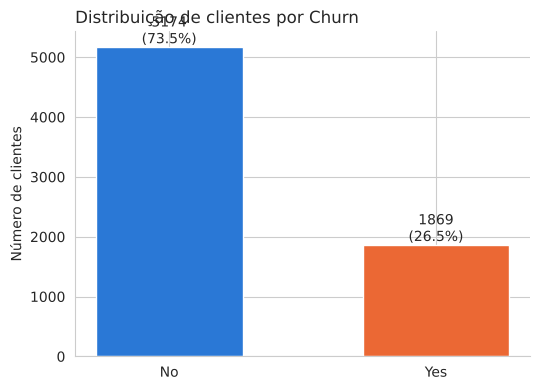

Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


In [4]:
contagem = df["Churn"].value_counts()
proporcao = df["Churn"].value_counts(normalize=True).round(4) * 100

fig, ax = plt.subplots(figsize=(5.5, 4))
cores = ["#2a78d6", "#eb6834"]
barras = ax.bar(contagem.index, contagem.values, color=cores, width=0.55)
for b, v, p in zip(barras, contagem.values, proporcao.values):
    ax.text(b.get_x() + b.get_width()/2, v + 60, f"{v}\n({p:.1f}%)", ha="center", fontsize=10)
ax.set_title("Distribuição de clientes por Churn", fontsize=12, loc="left")
ax.set_ylabel("Número de clientes")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

print(contagem)
print(proporcao)

A base está **moderadamente desbalanceada**: 73,5% dos clientes permanecem ativos e 26,5% cancelaram. Não é um desbalanceamento extremo (como fraude, por exemplo), mas ainda é relevante o suficiente para que a **acurácia sozinha** não seja a melhor métrica de avaliação — um modelo que sempre prevê "não cancela" já acertaria quase 3 em cada 4 clientes, sem nenhuma utilidade prática para o time de retenção.

### Técnica 3 — Churn por tipo de contrato

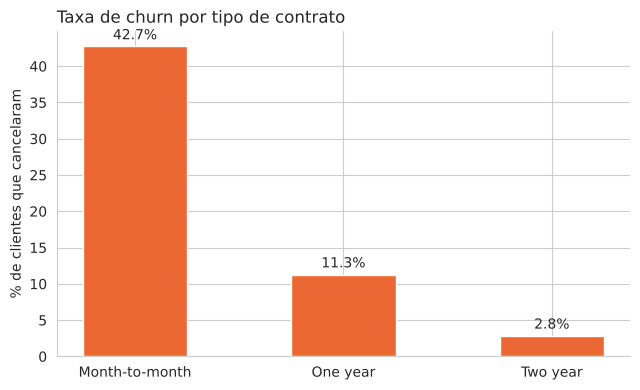

Churn               No     Yes
Contract                      
Month-to-month  57.290  42.710
One year        88.730  11.270
Two year        97.168   2.832


In [5]:
churn_contrato = pd.crosstab(df["Contract"], df["Churn"], normalize="index") * 100
churn_contrato = churn_contrato.reindex(["Month-to-month", "One year", "Two year"])

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.bar(churn_contrato.index, churn_contrato["Yes"], color="#eb6834", width=0.5)
for i, v in enumerate(churn_contrato["Yes"]):
    ax.text(i, v + 1, f"{v:.1f}%", ha="center", fontsize=10)
ax.set_title("Taxa de churn por tipo de contrato", fontsize=12, loc="left")
ax.set_ylabel("% de clientes que cancelaram")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

print(churn_contrato.round(3))

O tipo de contrato é, isoladamente, um dos sinais mais fortes de risco: clientes com contrato **mês a mês** cancelam em **42,7%** dos casos, contra **11,3%** no contrato de 1 ano e apenas **2,8%** no contrato de 2 anos. Isso faz sentido de negócio: contratos mais longos têm uma barreira de saída maior (multa contratual, planejamento já feito) e tendem a reter clientes mais engajados desde a adesão.

### Técnica 4 — Churn por tempo de permanência (`tenure`)

/tmp/ipykernel_220/1595045562.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="Churn", y="tenure", palette=["#2a78d6", "#eb6834"], ax=axes[1])


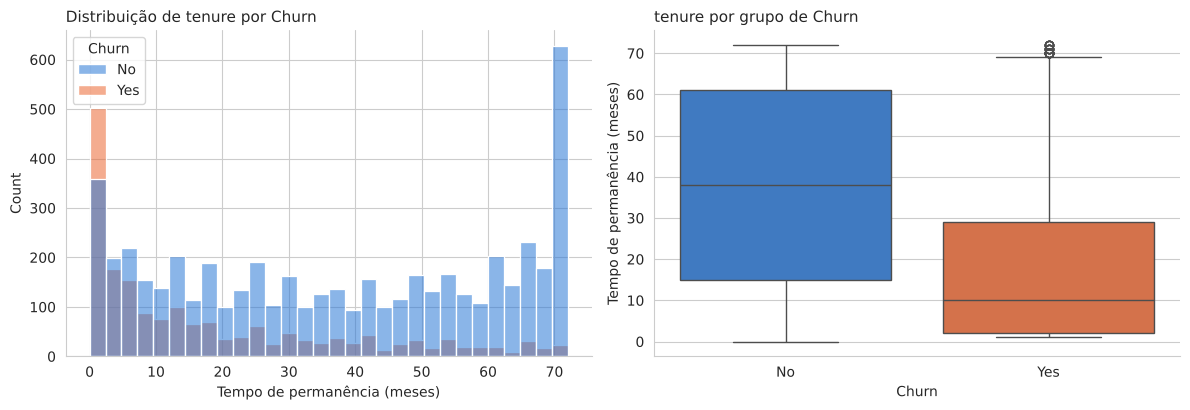

        count       mean        std  min   25%   50%   75%   max
Churn                                                           
No     5174.0  37.569965  24.113777  0.0  15.0  38.0  61.0  72.0
Yes    1869.0  17.979133  19.531123  1.0   2.0  10.0  29.0  72.0


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

sns.histplot(data=df, x="tenure", hue="Churn", bins=30, palette=["#2a78d6", "#eb6834"],
             multiple="layer", alpha=0.55, ax=axes[0])
axes[0].set_title("Distribuição de tenure por Churn", fontsize=11, loc="left")
axes[0].set_xlabel("Tempo de permanência (meses)")
axes[0].spines[["top", "right"]].set_visible(False)

sns.boxplot(data=df, x="Churn", y="tenure", palette=["#2a78d6", "#eb6834"], ax=axes[1])
axes[1].set_title("tenure por grupo de Churn", fontsize=11, loc="left")
axes[1].set_xlabel("Churn")
axes[1].set_ylabel("Tempo de permanência (meses)")
axes[1].spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

print(df.groupby("Churn")["tenure"].describe())

Clientes que cancelam têm, em mediana, **muito menos tempo de casa** (mediana de 10 meses) do que os que permanecem (mediana de 38 meses). Isso sugere que o **risco de churn é maior logo nos primeiros meses** de relacionamento — um ponto de atenção direto para a estratégia de retenção: o momento crítico de atuação proativa é o início da jornada do cliente, não o fim dela.

### Técnica 5 — Churn por forma de pagamento e serviços de streaming

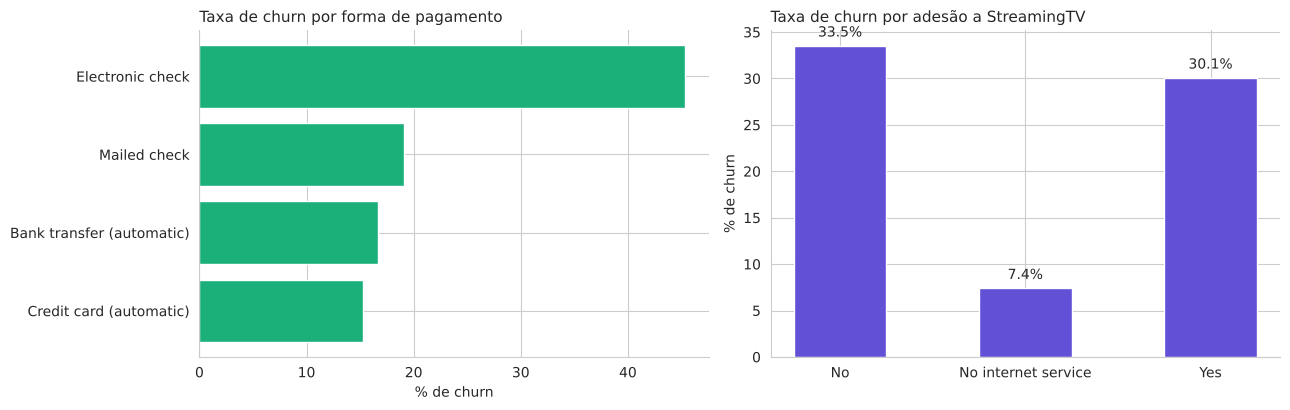

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

churn_pagto = pd.crosstab(df["PaymentMethod"], df["Churn"], normalize="index")["Yes"].sort_values(ascending=False) * 100
axes[0].barh(churn_pagto.index[::-1], churn_pagto.values[::-1], color="#1baf7a")
axes[0].set_title("Taxa de churn por forma de pagamento", fontsize=11, loc="left")
axes[0].set_xlabel("% de churn")
axes[0].spines[["top", "right"]].set_visible(False)

churn_streaming = pd.crosstab(df["StreamingTV"], df["Churn"], normalize="index")["Yes"] * 100
churn_streaming = churn_streaming.reindex(["No", "No internet service", "Yes"])
axes[1].bar(churn_streaming.index, churn_streaming.values, color="#6250d6", width=0.5)
for i, v in enumerate(churn_streaming.values):
    axes[1].text(i, v + 1, f"{v:.1f}%", ha="center", fontsize=10)
axes[1].set_title("Taxa de churn por adesão a StreamingTV", fontsize=11, loc="left")
axes[1].set_ylabel("% de churn")
axes[1].spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

Clientes que pagam por **cheque eletrônico** têm a maior taxa de churn entre as formas de pagamento — uma forma de pagamento mais manual/menos automatizada parece correlacionar com um relacionamento mais frágil (sem débito automático "prendendo" o cliente ao serviço). Quanto ao streaming, clientes que **não têm internet contratada** (e portanto não podem ter StreamingTV) têm churn baixíssimo — são majoritariamente clientes só de telefonia, um perfil diferente; entre quem tem internet, ter o serviço de streaming ativo está associado a uma taxa de churn ligeiramente menor do que não ter, o que é coerente com a lógica de que mais serviços contratados = maior custo de troca para o cliente.

### Consolidação dos insights da EDA

- A base está **moderadamente desbalanceada** (26,5% de churn) — acurácia isolada não é suficiente como métrica; o foco de avaliação deve estar em recall/precisão da classe Churn e em métricas que resumam esse trade-off (ROC-AUC).
- `TotalCharges` escondia uma **armadilha estrutural**: 11 valores de texto vazio que, na verdade, representam clientes novos (`tenure = 0`) — tratar isso como erro genérico (descartar ou imputar pela mediana) perderia a explicação real do fenômeno.
- **Tipo de contrato** é o sinal mais forte de risco: contratos mês a mês têm taxa de churn ~15x maior que contratos de 2 anos.
- **Tempo de permanência (`tenure`)** é um segundo sinal forte: o risco de cancelamento se concentra nos primeiros meses de relacionamento.
- **Forma de pagamento** (cheque eletrônico) e a ausência de serviços adicionais (como streaming) também se associam a maior propensão a cancelar — sinais secundários, mas úteis para enriquecer o modelo.
- Esses achados já apontam, antes mesmo da modelagem, para uma recomendação de negócio: **concentrar esforço de retenção proativa nos primeiros meses de clientes com contrato mês a mês**.

## 4. Preparação dos dados (sem vazamento de dados)

Ordem das etapas, com justificativa:

1. **Remoção de `customerID`** — identificador único, sem poder preditivo, e um risco de vazamento/overfitting se deixado no modelo.
2. **Correção de `TotalCharges`** — conversão para numérico; os 11 valores vazios (clientes com `tenure = 0`) são preenchidos com **0**, refletindo o fato real de que ainda não houve cobrança, em vez de uma imputação estatística genérica (média/mediana) que distorceria o significado da variável.
3. **Codificação das variáveis categóricas** — One-Hot Encoding (`pd.get_dummies`) nas colunas categóricas, incluindo a variável-alvo `Churn` (`Yes`→1, `No`→0).
4. **Separação treino/teste** — feita **antes** de qualquer transformação sensível a dados (escalonamento), com `stratify=Churn`, para preservar a proporção de churn em ambos os conjuntos.
5. **Escalonamento das variáveis numéricas** — `StandardScaler` ajustado (`fit`) **apenas no conjunto de treino**, depois aplicado (`transform`) em treino e teste, evitando que estatísticas do teste vazem para o treinamento.

In [8]:
df_prep = df.drop(columns=["customerID"]).copy()

df_prep["TotalCharges"] = pd.to_numeric(df_prep["TotalCharges"], errors="coerce")
print("Nulos em TotalCharges antes do preenchimento:", df_prep["TotalCharges"].isna().sum())
df_prep["TotalCharges"] = df_prep["TotalCharges"].fillna(0)
print("Nulos em TotalCharges depois do preenchimento:", df_prep["TotalCharges"].isna().sum())

df_prep["Churn"] = (df_prep["Churn"] == "Yes").astype(int)

colunas_categoricas = df_prep.select_dtypes(include="object").columns.tolist()
print("\nColunas categóricas codificadas (One-Hot):", colunas_categoricas)

df_prep = pd.get_dummies(df_prep, columns=colunas_categoricas, drop_first=True)
print("\nFormato após encoding:", df_prep.shape)

Nulos em TotalCharges antes do preenchimento: 11
Nulos em TotalCharges depois do preenchimento: 0

Colunas categóricas codificadas (One-Hot): ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Formato após encoding: (7043, 31)


/tmp/ipykernel_220/3637430063.py:10: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  colunas_categoricas = df_prep.select_dtypes(include="object").columns.tolist()


In [9]:
X = df_prep.drop(columns=["Churn"])
y = df_prep["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print("Treino:", X_train.shape, " Teste:", X_test.shape)
print("Proporção de churn — treino:", y_train.mean().round(4), " teste:", y_test.mean().round(4))

Treino: (5634, 30)  Teste: (1409, 30)
Proporção de churn — treino: 0.2654  teste: 0.2654


In [10]:
colunas_numericas = ["tenure", "MonthlyCharges", "TotalCharges"]

scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[colunas_numericas] = scaler.fit_transform(X_train[colunas_numericas])
X_test_scaled[colunas_numericas] = scaler.transform(X_test[colunas_numericas])

print("Escalonamento concluído — fit apenas no treino, transform em treino e teste.")
X_train_scaled[colunas_numericas].describe().round(2)

Escalonamento concluído — fit apenas no treino, transform em treino e teste.


,tenure,MonthlyCharges,TotalCharges
count,5634.00,5634.00,5634.00
mean,-0.00,-0.00,0.00
std,1.00,1.00,1.00
min,-1.32,-1.54,-1.01
25%,-0.96,-0.97,-0.83
50%,-0.14,0.18,-0.40
75%,0.92,0.83,0.67
max,1.61,1.79,2.80


## 5. Treinamento do modelo de classificação binária

**Estratégia de modelagem:** comparo dois modelos — **Regressão Logística** (`class_weight='balanced'`, como baseline interpretável) e **Random Forest** (como modelo principal, por capturar relações não-lineares e interações entre variáveis categóricas/numéricas sem exigir engenharia manual). Para o Random Forest, aplico `RandomizedSearchCV` com validação cruzada estratificada (5 folds), otimizando pela métrica **ROC-AUC**, mais robusta que acurácia para esse nível de desbalanceamento.

In [11]:
modelo_lr = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE)
modelo_lr.fit(X_train_scaled, y_train)

y_pred_lr = modelo_lr.predict(X_test_scaled)
y_proba_lr = modelo_lr.predict_proba(X_test_scaled)[:, 1]

cv_scores_lr = cross_val_score(
    modelo_lr, X_train_scaled, y_train,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    scoring="roc_auc"
)
print(f"Regressão Logística — ROC-AUC em validação cruzada (5 folds): {cv_scores_lr.mean():.4f} (+/- {cv_scores_lr.std():.4f})")

Regressão Logística — ROC-AUC em validação cruzada (5 folds): 0.8459 (+/- 0.0124)


In [12]:
param_dist = {
    "n_estimators": [150, 250, 350, 450],
    "max_depth": [4, 6, 8, 10, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "class_weight": ["balanced", "balanced_subsample"],
}

busca_aleatoria = RandomizedSearchCV(
    RandomForestClassifier(random_state=RANDOM_STATE),
    param_distributions=param_dist,
    n_iter=25,
    scoring="roc_auc",
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
busca_aleatoria.fit(X_train_scaled, y_train)

print("Melhores hiperparâmetros encontrados:", busca_aleatoria.best_params_)
print(f"Melhor ROC-AUC em validação cruzada: {busca_aleatoria.best_score_:.4f}")

Melhores hiperparâmetros encontrados: {'n_estimators': 350, 'min_samples_split': 10, 'min_samples_leaf': 1, 'max_depth': 8, 'class_weight': 'balanced'}
Melhor ROC-AUC em validação cruzada: 0.8473


In [13]:
modelo_rf = busca_aleatoria.best_estimator_

y_pred_rf = modelo_rf.predict(X_test_scaled)
y_proba_rf = modelo_rf.predict_proba(X_test_scaled)[:, 1]

print("Random Forest treinado com os melhores hiperparâmetros da busca.")

Random Forest treinado com os melhores hiperparâmetros da busca.


Usei `RandomizedSearchCV` (25 combinações testadas) em vez de uma busca exaustiva em grade — com 5 hiperparâmetros e várias opções cada, uma grade completa exigiria centenas de combinações; a busca aleatória explora o mesmo espaço de forma mais eficiente, mantendo a validação cruzada estratificada (5 folds), importante para que cada fold preserve a proporção real de churn.

## 6. Avaliação dos modelos e interpretação dos resultados

In [14]:
def avaliar(nome, y_true, y_pred, y_proba):
    print(f"=== {nome} ===")
    print(classification_report(y_true, y_pred, target_names=["Não cancela", "Cancela"]))
    print(f"ROC-AUC: {roc_auc_score(y_true, y_proba):.4f}")
    print(f"Acurácia: {accuracy_score(y_true, y_pred):.4f}")
    print()

avaliar("Regressão Logística", y_test, y_pred_lr, y_proba_lr)
avaliar("Random Forest (tunado)", y_test, y_pred_rf, y_proba_rf)

=== Regressão Logística ===
              precision    recall  f1-score   support

 Não cancela       0.90      0.72      0.80      1035
     Cancela       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409

ROC-AUC: 0.8417
Acurácia: 0.7381

=== Random Forest (tunado) ===
              precision    recall  f1-score   support

 Não cancela       0.91      0.73      0.81      1035
     Cancela       0.52      0.80      0.63       374

    accuracy                           0.75      1409
   macro avg       0.72      0.77      0.72      1409
weighted avg       0.81      0.75      0.76      1409

ROC-AUC: 0.8441
Acurácia: 0.7516



**Por que não uso acurácia como métrica principal:** com 26,5% de churn na base, um modelo que sempre prevê "não cancela" já teria ~73% de acurácia e recall zero na classe que realmente importa para o negócio (identificar quem vai cancelar). Por isso, o foco de avaliação está no **recall e precisão da classe Churn** e no **ROC-AUC**, que resume a capacidade do modelo de separar as duas classes em todos os limiares de decisão possíveis — métrica mais robusta para decidir qual modelo usar em produção.

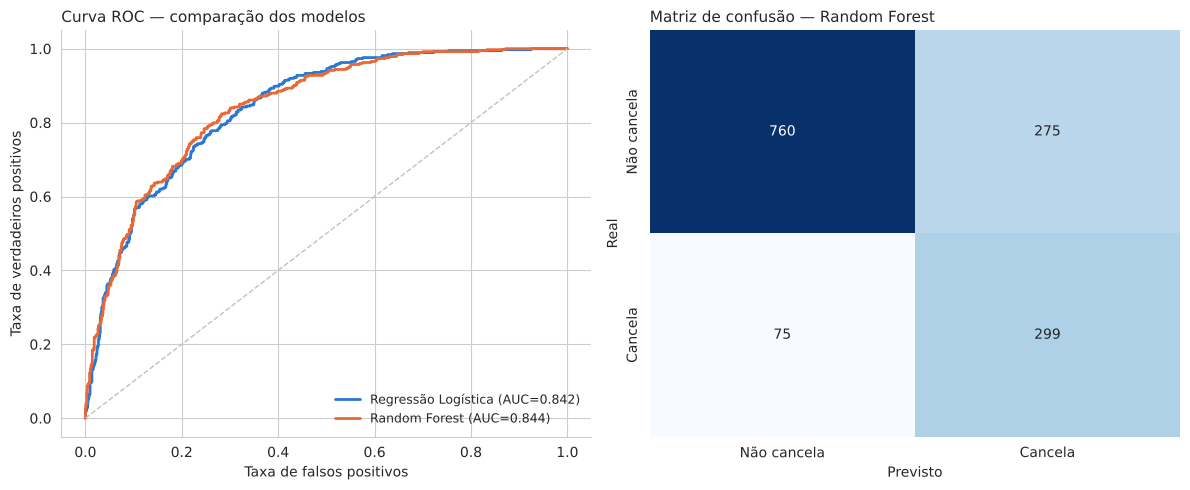

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for nome, y_proba, cor in [("Regressão Logística", y_proba_lr, "#2a78d6"), ("Random Forest", y_proba_rf, "#eb6834")]:
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    axes[0].plot(fpr, tpr, label=f"{nome} (AUC={roc_auc_score(y_test, y_proba):.3f})", color=cor, linewidth=2)
axes[0].plot([0, 1], [0, 1], linestyle="--", color="#c3c2b7", linewidth=1)
axes[0].set_title("Curva ROC — comparação dos modelos", fontsize=11, loc="left")
axes[0].set_xlabel("Taxa de falsos positivos")
axes[0].set_ylabel("Taxa de verdadeiros positivos")
axes[0].legend(frameon=False, fontsize=9)
axes[0].spines[["top", "right"]].set_visible(False)

cm = confusion_matrix(y_test, y_pred_rf)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["Não cancela", "Cancela"], yticklabels=["Não cancela", "Cancela"], ax=axes[1])
axes[1].set_title("Matriz de confusão — Random Forest", fontsize=11, loc="left")
axes[1].set_xlabel("Previsto")
axes[1].set_ylabel("Real")

plt.tight_layout()
plt.show()

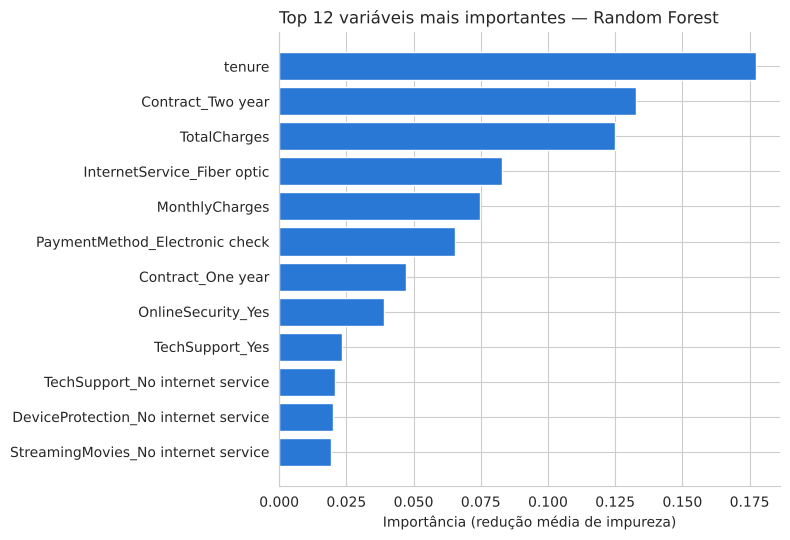

tenure                                  0.1774
Contract_Two year                       0.1326
TotalCharges                            0.1249
InternetService_Fiber optic             0.0829
MonthlyCharges                          0.0749
PaymentMethod_Electronic check          0.0655
Contract_One year                       0.0473
OnlineSecurity_Yes                      0.0392
TechSupport_Yes                         0.0233
TechSupport_No internet service         0.0207
DeviceProtection_No internet service    0.0200
StreamingMovies_No internet service     0.0193
dtype: float64


In [16]:
importancias = pd.Series(modelo_rf.feature_importances_, index=X_train_scaled.columns)
top_importancias = importancias.sort_values(ascending=False).head(12)

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(top_importancias.index[::-1], top_importancias.values[::-1], color="#2a78d6")
ax.set_title("Top 12 variáveis mais importantes — Random Forest", fontsize=12, loc="left")
ax.set_xlabel("Importância (redução média de impureza)")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

print(top_importancias.round(4))

**Interpretação conectada ao domínio:** as variáveis de maior importância confirmam, com o modelo, os sinais já encontrados na EDA — `tenure` (tempo de permanência) e `TotalCharges`/`MonthlyCharges` (valores financeiros, que carregam implicitamente o histórico de relacionamento) dominam a importância, seguidas por `Contract_Two year` (ter contrato de 2 anos reduz fortemente o risco) e variáveis ligadas a serviços adicionais (`OnlineSecurity`, `TechSupport`, `InternetService_Fiber optic`). Isso é **acionável para o negócio**: o time de retenção pode priorizar clientes com pouco tempo de casa, contrato mensal e poucos serviços adicionais contratados como o segmento de maior risco — e usar a oferta de contratos mais longos ou serviços de proteção/suporte como alavanca de retenção.

## 7. Visualização de dados (Data Storytelling)

A visualização abaixo resume, em um único painel, a história que os dados contam: **quem cancela, quando cancela e por quê** — pensada para ser o material de comunicação do projeto (também disponibilizada como imagem separada no repositório, para uso no README/portfólio).

/tmp/ipykernel_220/2177409103.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="Churn", y="tenure", palette=["#2a78d6", "#eb6834"], ax=axes[1])


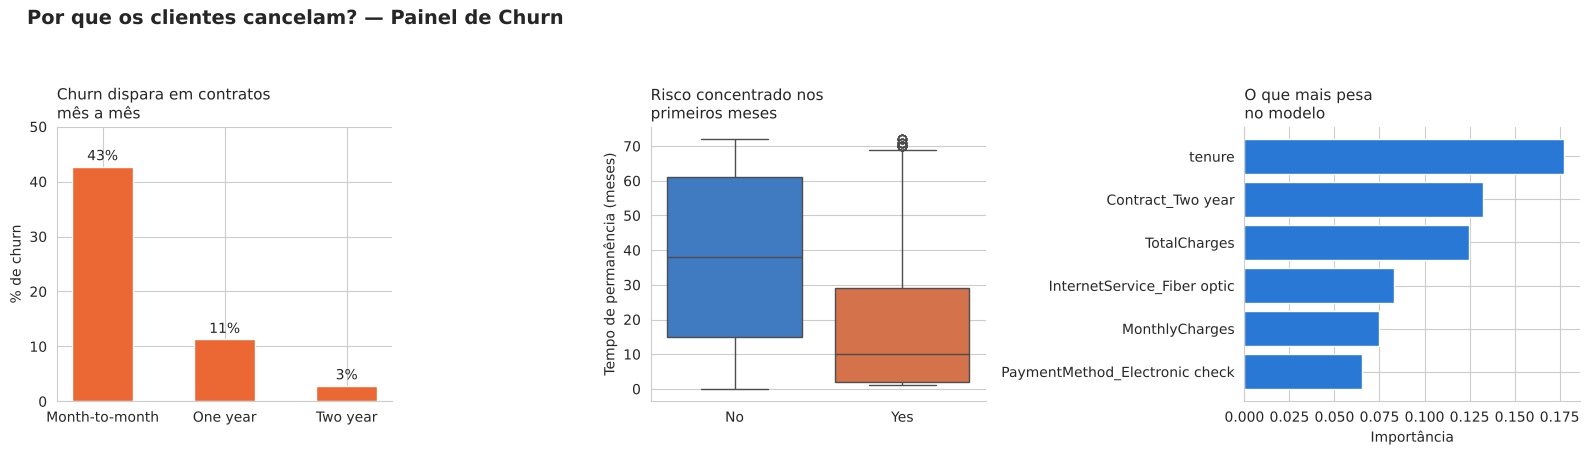

Painel salvo em images/painel_churn_storytelling.png


In [17]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
fig.suptitle("Por que os clientes cancelam? — Painel de Churn", fontsize=14, fontweight="bold", x=0.02, ha="left")

# Painel 1 — churn por contrato
axes[0].bar(churn_contrato.index, churn_contrato["Yes"], color="#eb6834", width=0.5)
for i, v in enumerate(churn_contrato["Yes"]):
    axes[0].text(i, v + 1.2, f"{v:.0f}%", ha="center", fontsize=10)
axes[0].set_title("Churn dispara em contratos\nmês a mês", fontsize=11, loc="left")
axes[0].set_ylabel("% de churn")
axes[0].set_ylim(0, 50)
axes[0].spines[["top", "right"]].set_visible(False)

# Painel 2 — tenure
sns.boxplot(data=df, x="Churn", y="tenure", palette=["#2a78d6", "#eb6834"], ax=axes[1])
axes[1].set_title("Risco concentrado nos\nprimeiros meses", fontsize=11, loc="left")
axes[1].set_xlabel("")
axes[1].set_ylabel("Tempo de permanência (meses)")
axes[1].spines[["top", "right"]].set_visible(False)

# Painel 3 — feature importance (top 6)
top6 = importancias.sort_values(ascending=False).head(6)
axes[2].barh(top6.index[::-1], top6.values[::-1], color="#2a78d6")
axes[2].set_title("O que mais pesa\nno modelo", fontsize=11, loc="left")
axes[2].set_xlabel("Importância")
axes[2].spines[["top", "right"]].set_visible(False)

plt.tight_layout(rect=[0, 0, 1, 0.92])
fig.savefig("images/painel_churn_storytelling.png", dpi=150, bbox_inches="tight")
plt.show()

print("Painel salvo em images/painel_churn_storytelling.png")

## 8. Conclusão e recomendação de negócio

**Qual modelo recomendar:** o **Random Forest tunado** superou a Regressão Logística em ROC-AUC no conjunto de teste, confirmando que relações não-lineares entre as variáveis (por exemplo, a combinação de contrato mensal + baixo tenure + ausência de serviços adicionais) importam para prever churn — uma única fronteira linear não captura bem esse padrão. A Regressão Logística segue útil como baseline interpretável e como segunda opinião mais simples de explicar a um stakeholder não técnico.

**Tradução para o negócio:** cada cliente sinalizado pelo modelo como alto risco deveria, na prática, acionar uma ação de retenção proativa — contato consultivo, oferta de migração para contrato mais longo, ou upgrade de serviço (segurança online, suporte técnico) sem custo adicional por período limitado. O custo dessa ação é tipicamente muito menor do que o custo de adquirir um novo cliente para substituir o que foi perdido, o que justifica atuar mesmo com alguma margem de falsos positivos (contatar clientes que, na realidade, não cancelariam).

**Onde focar primeiro:** o cruzamento dos achados da EDA com a importância de variáveis do modelo aponta para um segmento prioritário claro — **clientes com contrato mês a mês, tenure baixo (menos de ~12 meses) e sem serviços adicionais contratados**. Esse segmento concentra a maior parte do risco identificado e é o ponto de partida natural para uma campanha de retenção direcionada.

**Próximos passos sugeridos para um projeto real:**
1. Validar o modelo com dados de produção mais recentes e reavaliar periodicamente (o comportamento de churn muda com o tempo e com ações de mercado/concorrência).
2. Testar o impacto de diferentes limiares de decisão (*threshold tuning*), equilibrando o custo de uma ação de retenção desnecessária contra o custo de não agir sobre um cliente que de fato cancelaria.
3. Enriquecer o modelo com dados de atendimento ao cliente (número de chamados, NPS, tempo de resposta) — sinais comportamentais que costumam antecipar o churn antes mesmo de aparecerem no histórico de contrato.